# Bassez et al. 2021 — Breast Cancer
## 04 · EMT-TF expression (unconditional final step)

Gate 2 GO (non-branching), Gate 3 NA → the branching-only 04_correlation / 05_modules notebooks are **not** produced; the unconditional EMT-TF expression step is the final notebook, renumbered to 04 (§6). Categorical overlay of thresholded EMT-TF expressers on the grey manifold. Panel candidates span the Snail/Zeb/Twist, **FOXC**, and **PRRX** families (VIM is a mesenchymal marker, not a TF → excluded). TFs are gated on detectable expression; the two most pseudotime-separated expressed factors (early/root vs late/terminus) are shown.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout, consistent orientation
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 13834 | pseudotime range 0.0 -> 10.93


### Candidate EMT-TF panel — detection-gated, scored by pseudotime position
Report detection fraction, early/late means, and rho vs pseudotime; keep factors expressed in >3% of cells; pick the two with the largest pseudotime separation (early/root vs late/terminus).

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel genes present:', present)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print('\nderived pair: %s (early/root) <-> %s (late/terminus)' % (early_tf, late_tf))

panel genes present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.050       0.017      0.008    -0.090    EARLY(root)
 FOXC2      0.037       0.013      0.006    -0.070    EARLY(root)
 PRRX2      0.020       0.006      0.004    -0.064    EARLY(root)
 SNAI1      0.020       0.007      0.004    -0.058    EARLY(root)
  ZEB1      0.014       0.006      0.005    -0.047    EARLY(root)
  ZEB2      0.009       0.009      0.004    -0.039    EARLY(root)
 PRRX1      0.025       0.008      0.009    -0.031 LATE(terminus)
TWIST1      0.007       0.002      0.002    -0.026 LATE(terminus)
TWIST2      0.006       0.001      0.002    -0.009 LATE(terminus)
 SNAI2      0.074       0.039      0.067    -0.004 LATE(terminus)

derived pair: FOXC1 (early/root) <-> SNAI2 (late/terminus)


### Categorical overlay on the grey manifold (deliverable)
Display cutoff = upper quartile among expressers (set, not outlier-dominated); thresholded expressers coloured over all cells in grey. House style (3.5,1.5).

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.33, 'SNAI2': 1.307} | cells shown: {'FOXC1': 173, 'SNAI2': 254}
FOXC1: 5.0% expressing; 173 shown; mean pseudotime of shown = 0.48 (all = 0.53)
SNAI2: 7.4% expressing; 254 shown; mean pseudotime of shown = 0.68 (all = 0.53)
saved expression.pdf


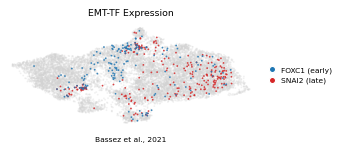

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in thr},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=f'{early_tf} (early)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=f'{late_tf} (late)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown; mean pseudotime of shown = %.2f (all = %.2f)' % (
          g, (vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
print('saved expression.pdf')